In [8]:
import torch
import timm
import cv2
import sklearn
import matplotlib
import seaborn

print("All packages imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

All packages imported successfully!
PyTorch version: 2.11.0+cu128
GPU available: True


In [9]:
%pip install timm opencv-python-headless scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("\nFolder:", root)

    for file in files[:10]:
        print("  ", file)


Folder: /kaggle/input

Folder: /kaggle/input/notebooks

Folder: /kaggle/input/notebooks/aframannan

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection
   __notebook__.ipynb
   __output__.json
   __results__.html
   cnn_lstm_deepfake_detector.h5
   custom.css

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/__results___files
   __results___11_0.png
   __results___11_1.png
   __results___22_0.png
   __results___23_1.png
   __results___24_0.png

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake
   0000_fake.npy
   0001_fake.npy
   0002_fake.npy
   0003_fake.npy
   0004_fake.npy
   0005_fake.npy
   0006_fake.npy
   0007_fake.npy
   0008_fake.npy
   0009_fake.npy

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/0000_fake
   frame_000.jpg
   frame_001.jpg
   frame_002.jpg
   frame_003.jpg
   frame_004.jpg
   frame_005.jpg
   frame

In [11]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Notebook Settings if available.")

GPU available: True
GPU name: Tesla T4


In [12]:
import os

print("========== KAGGLE INPUT DATASETS ==========")

for root, dirs, files in os.walk("/kaggle/input"):
    video_files = [
        f for f in files
        if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
    ]

    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if video_files or image_files:
        print("\nFolder:", root)
        print("Videos:", len(video_files))
        print("Images:", len(image_files))
        print("Sample files:", (video_files + image_files)[:5])

print("\n========== KAGGLE WORKING DIRECTORY ==========")

for root, dirs, files in os.walk("/kaggle/working"):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print("\nFolder:", root)
        print("Images:", len(image_files))
        print("Sample:", image_files[:5])

========== KAGGLE INPUT DATASETS ==========

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/__results___files
Videos: 0
Images: 5
Sample files: ['__results___11_0.png', '__results___11_1.png', '__results___22_0.png', '__results___23_1.png', '__results___24_0.png']

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/0000_fake
Videos: 0
Images: 30
Sample files: ['frame_000.jpg', 'frame_001.jpg', 'frame_002.jpg', 'frame_003.jpg', 'frame_004.jpg']

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/0001_fake
Videos: 0
Images: 30
Sample files: ['frame_000.jpg', 'frame_001.jpg', 'frame_002.jpg', 'frame_003.jpg', 'frame_004.jpg']

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/0002_fake
Videos: 0
Images: 30
Sample files: ['frame_000.jpg', 'frame_001.jpg', 'frame_002.jpg', 'frame_003.jpg', 'frame_004.jpg']

Folder: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/000

In [13]:
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed"
)

REAL_DIR = DATA_DIR / "real"
FAKE_DIR = DATA_DIR / "fake"

print("Real directory exists:", REAL_DIR.exists())
print("Fake directory exists:", FAKE_DIR.exists())

print("Real video folders:", len(list(REAL_DIR.iterdir())))
print("Fake video folders:", len(list(FAKE_DIR.iterdir())))

Real directory exists: True
Fake directory exists: True
Real video folders: 98
Fake video folders: 98


In [14]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

real_images = [
    p for p in REAL_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

fake_images = [
    p for p in FAKE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Total real images:", len(real_images))
print("Total fake images:", len(fake_images))
print("Total images:", len(real_images) + len(fake_images))

Total real images: 1470
Total fake images: 1470
Total images: 2940


In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

records = []

for class_name, class_dir, label in [
    ("real", REAL_DIR, 0),
    ("fake", FAKE_DIR, 1)
]:
    for video_folder in sorted(class_dir.iterdir()):
        if not video_folder.is_dir():
            continue

        images = [
            p for p in video_folder.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        if images:
            records.append({
                "video_id": f"{class_name}_{video_folder.name}",
                "class_name": class_name,
                "label": label,
                "folder": str(video_folder),
                "num_frames": len(images)
            })

videos_df = pd.DataFrame(records)

train_df, temp_df = train_test_split(
    videos_df,
    test_size=0.30,
    random_state=SEED,
    stratify=videos_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Training videos:", len(train_df))
print("Validation videos:", len(val_df))
print("Testing videos:", len(test_df))

print("\nTraining distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts())

print("\nTesting distribution:")
print(test_df["class_name"].value_counts())

Training videos: 68
Validation videos: 15
Testing videos: 15

Training distribution:
class_name
fake    34
real    34
Name: count, dtype: int64

Validation distribution:
class_name
fake    8
real    7
Name: count, dtype: int64

Testing distribution:
class_name
real    8
fake    7
Name: count, dtype: int64


In [16]:
import torch
import torch.nn as nn
import timm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=2
)

model = model.to(DEVICE)

print("Vision Transformer loaded successfully!")

Using device: cuda


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Vision Transformer loaded successfully!


In [17]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import torch

IMAGE_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DeepfakeDataset(Dataset):
    def __init__(self, video_df, transform=None):
        self.samples = []
        self.transform = transform

        for row in video_df.itertuples():
            folder = Path(row.folder)
            label = int(row.label)

            for image_path in folder.iterdir():
                if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                    self.samples.append((image_path, label))

        self.samples.sort(key=lambda item: str(item[0]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, label = self.samples[idx]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = DeepfakeDataset(train_df, train_transform)
val_dataset = DeepfakeDataset(val_df, eval_transform)
test_dataset = DeepfakeDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 2040
Validation images: 450
Testing images: 450


In [18]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels.tolist())

print("Image batch device before transfer:", images.device)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Labels in batch: [1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0]
Image batch device before transfer: cpu


In [19]:
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE)

# Training configuration
EPOCHS = 3
LEARNING_RATE = 2e-5

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# Save model outputs
OUTPUT_DIR = Path("/kaggle/working/project2_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = OUTPUT_DIR / "best_vit_model.pth"

best_val_loss = float("inf")
history = []


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in tqdm(loader, leave=False):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


for epoch in range(EPOCHS):

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        optimizer
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Training loss:      {train_loss:.4f}")
    print(f"Training accuracy:  {train_acc:.4f}")
    print(f"Validation loss:    {val_loss:.4f}")
    print(f"Validation accuracy:{val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": model.state_dict(),
            "model_name": "vit_base_patch16_224",
            "class_to_idx": {"real": 0, "fake": 1},
            "image_size": 224
        }, BEST_MODEL_PATH)

        print("Best model checkpoint saved.")

history_df = pd.DataFrame(history)

print("\nTraining complete!")
print("Model saved to:", BEST_MODEL_PATH)

display(history_df)

  0%|          | 0/128 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]


Epoch 1/3
Training loss:      0.2270
Training accuracy:  0.8882
Validation loss:    0.9483
Validation accuracy:0.7000
Best model checkpoint saved.


  0%|          | 0/128 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe7b53498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe7b53498a0>self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():
self._shutdown_workers()  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorif w.is_alive():: 
can only test a child process  File "/usr/lib/p

...

  0%|          | 0/128 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fe7b53498a0>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7fe7b53498a0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only te


Epoch 3/3
Training loss:      0.0203
Training accuracy:  0.9902
Validation loss:    1.0538
Validation accuracy:0.7489

Training complete!
Model saved to: /kaggle/working/project2_artifacts/best_vit_model.pth


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.226962,0.888235,0.948288,0.700000
1,2,0.026584,0.986275,1.331415,0.708889
2,3,0.020257,0.990196,1.053794,0.748889


In [20]:
from torch.utils.data import DataLoader
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

BEST_MODEL_PATH = Path(
    "/kaggle/working/project2_artifacts/best_vit_model.pth"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Saved model loaded successfully!")
print("Device:", DEVICE)
print("Test frames:", len(test_dataset))

Saved model loaded successfully!
Device: cuda
Test frames: 450


  0%|          | 0/29 [00:00<?, ?it/s]

TEST RESULTS
frame_accuracy: 0.9289 (92.89%)
frame_precision: 0.8739 (87.39%)
frame_recall: 0.9905 (99.05%)
frame_f1: 0.9286 (92.86%)
frame_roc_auc: 0.9982 (99.82%)

Classification report:
              precision    recall  f1-score   support

        Real       0.99      0.88      0.93       240
        Fake       0.87      0.99      0.93       210

    accuracy                           0.93       450
   macro avg       0.93      0.93      0.93       450
weighted avg       0.94      0.93      0.93       450



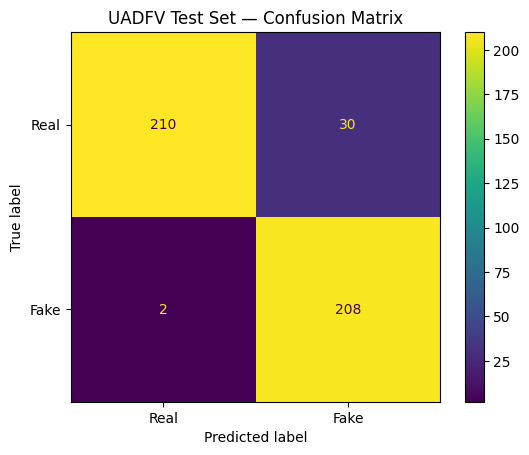

In [21]:
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import json

all_labels = []
all_predictions = []
all_fake_probabilities = []

model.eval()

with torch.no_grad():
    for images, labels in tqdm(test_loader):

        images = images.to(DEVICE)
        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_fake_probabilities.extend(
            probabilities[:, 1].cpu().numpy().tolist()
        )

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, zero_division=0
)
recall = recall_score(
    all_labels, all_predictions, zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions, zero_division=0
)

metrics = {
    "frame_accuracy": float(accuracy),
    "frame_precision": float(precision),
    "frame_recall": float(recall),
    "frame_f1": float(f1)
}

if len(set(all_labels)) == 2:
    metrics["frame_roc_auc"] = float(
        roc_auc_score(all_labels, all_fake_probabilities)
    )

print("TEST RESULTS")
print("=" * 40)

for name, value in metrics.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
).plot()

plt.title("UADFV Test Set — Confusion Matrix")
plt.show()

with open(
    "/kaggle/working/project2_artifacts/test_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=2)

In [22]:
%pip install -q grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [23]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

test_images = [
    p for p, label in test_dataset.samples
]

print("Total test images:", len(test_images))
print("Example image:", test_images[0])

Total test images: 450
Example image: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/0001_fake/frame_000.jpg


Selected image: /kaggle/input/notebooks/aframannan/deepfake-detection/preprocessed/fake/0001_fake/frame_000.jpg
Input shape: torch.Size([1, 3, 224, 224])


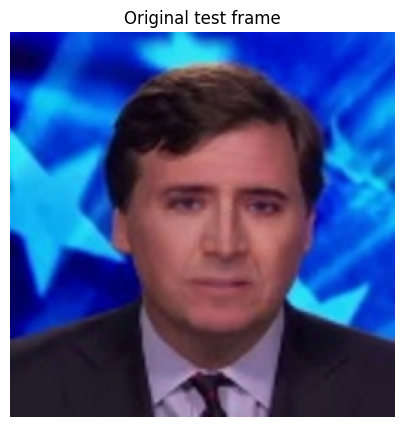

In [25]:
from torchvision import transforms

IMAGE_SIZE = 224

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

IMAGE_PATH = test_images[0]

image = Image.open(IMAGE_PATH).convert("RGB")
image = image.resize((IMAGE_SIZE, IMAGE_SIZE))

rgb_image = np.asarray(image).astype(np.float32) / 255.0
input_tensor = eval_transform(image).unsqueeze(0)

print("Selected image:", IMAGE_PATH)
print("Input shape:", input_tensor.shape)

plt.figure(figsize=(5, 5))
plt.imshow(rgb_image)
plt.title("Original test frame")
plt.axis("off")
plt.show()

Predicted class: Fake
Real probability: 0.0008
Fake probability: 0.9992


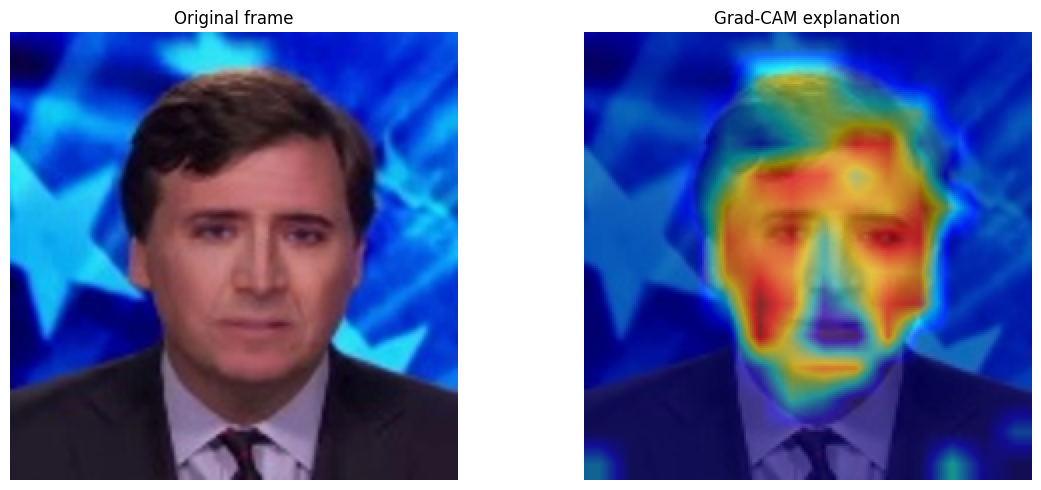

In [26]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.eval()

# Last ViT block's normalization layer
target_layers = [model.blocks[-1].norm1]

def reshape_transform(tensor):
    # Remove the class token
    tensor = tensor[:, 1:, :]

    batch_size, num_patches, channels = tensor.shape
    height = width = int(num_patches ** 0.5)

    tensor = tensor.reshape(
        batch_size, height, width, channels
    )

    # Convert to [batch, channels, height, width]
    return tensor.permute(0, 3, 1, 2)


# First obtain the model's prediction
with torch.no_grad():
    logits = model(input_tensor.to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_class = int(probabilities.argmax().item())

# Grad-CAM requires gradients, so do not wrap this section in no_grad().
with GradCAM(
    model=model,
    target_layers=target_layers,
    reshape_transform=reshape_transform
) as cam:

    grayscale_cam = cam(
        input_tensor=input_tensor.to(DEVICE),
        targets=[ClassifierOutputTarget(predicted_class)]
    )[0]

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

print("Predicted class:", "Fake" if predicted_class == 1 else "Real")
print("Real probability:", round(probabilities[0].item(), 4))
print("Fake probability:", round(probabilities[1].item(), 4))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title("Grad-CAM explanation")
plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
from pathlib import Path
from PIL import Image

OUTPUT_DIR = Path("/kaggle/working/project2_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

heatmap_path = OUTPUT_DIR / "gradcam_explanation.png"

Image.fromarray(visualization).save(heatmap_path)

print("Grad-CAM image saved to:", heatmap_path)

Grad-CAM image saved to: /kaggle/working/project2_artifacts/gradcam_explanation.png


In [28]:
%pip install -q open_clip_torch

Note: you may need to restart the kernel to use updated packages.


In [29]:
import torch
import open_clip

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("GPU available:", torch.cuda.is_available())

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")

clip_model = clip_model.to(DEVICE)
clip_model.eval()

print("CLIP loaded successfully!")
print("Device:", DEVICE)

GPU available: True


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP loaded successfully!
Device: cuda


A genuine, unaltered video frame of a person. Similarity: 0.2549
A manipulated deepfake video frame of a person. Similarity: 0.2614


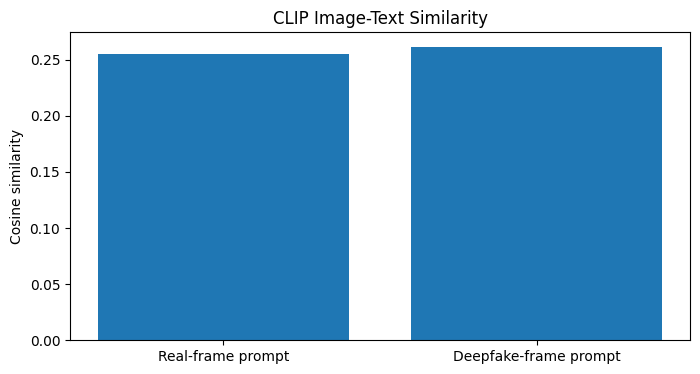

In [31]:
import torch
import matplotlib.pyplot as plt
from PIL import Image

prompts = [
    "A genuine, unaltered video frame of a person.",
    "A manipulated deepfake video frame of a person."
]

# Use the same test image selected for Grad-CAM
image = Image.open(IMAGE_PATH).convert("RGB")

image_tensor = clip_preprocess(image).unsqueeze(0).to(DEVICE)
text_tokens = clip_tokenizer(prompts).to(DEVICE)

with torch.no_grad():
    image_features = clip_model.encode_image(image_tensor)
    text_features = clip_model.encode_text(text_tokens)

    image_features = image_features / image_features.norm(
        dim=-1, keepdim=True
    )
    text_features = text_features / text_features.norm(
        dim=-1, keepdim=True
    )

    similarities = (
        image_features @ text_features.T
    ).squeeze(0)

for prompt, score in zip(prompts, similarities.cpu().tolist()):
    print(f"{prompt} Similarity: {score:.4f}")

plt.figure(figsize=(8, 4))
plt.bar(
    ["Real-frame prompt", "Deepfake-frame prompt"],
    similarities.cpu().tolist()
)
plt.ylabel("Cosine similarity")
plt.title("CLIP Image-Text Similarity")
plt.show()

VIDEO-LEVEL RESULTS
Videos evaluated: 15
Accuracy: 0.9333
Precision: 0.875
Recall: 1.0
F1 score: 0.9333
ROC-AUC: 1.0

Classification report:
              precision    recall  f1-score   support

        Real       1.00      0.88      0.93         8
        Fake       0.88      1.00      0.93         7

    accuracy                           0.93        15
   macro avg       0.94      0.94      0.93        15
weighted avg       0.94      0.93      0.93        15



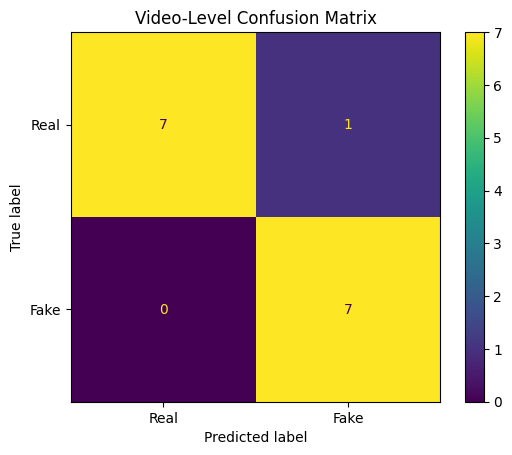

Video-level predictions saved.


In [32]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import torch

video_results = []

model.eval()

with torch.no_grad():
    for row in test_df.itertuples():
        video_folder = Path(row.folder)
        frame_paths = sorted([
            p for p in video_folder.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ])

        frame_fake_scores = []

        for frame_path in frame_paths:
            with Image.open(frame_path) as img:
                frame = img.convert("RGB")

            tensor = eval_transform(frame).unsqueeze(0).to(DEVICE)

            logits = model(tensor)
            probs = torch.softmax(logits, dim=1)

            frame_fake_scores.append(probs[0, 1].item())

        if not frame_fake_scores:
            continue

        video_fake_score = float(np.mean(frame_fake_scores))

        video_results.append({
            "video_id": row.video_id,
            "true_label": int(row.label),
            "fake_score": video_fake_score,
            "predicted_label": int(video_fake_score >= 0.5),
            "frames_evaluated": len(frame_fake_scores)
        })

video_results_df = pd.DataFrame(video_results)

y_true = video_results_df["true_label"]
y_pred = video_results_df["predicted_label"]
y_score = video_results_df["fake_score"]

print("VIDEO-LEVEL RESULTS")
print("=" * 40)

print("Videos evaluated:", len(video_results_df))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1 score:", round(f1_score(y_true, y_pred, zero_division=0), 4))

if y_true.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_true, y_score), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
).plot()

plt.title("Video-Level Confusion Matrix")
plt.show()

video_results_df.to_csv(
    "/kaggle/working/project2_artifacts/video_level_results.csv",
    index=False
)

print("Video-level predictions saved.")

In [33]:
import json
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/project2_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save training history
history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

# Save frame-level metrics
with open(OUTPUT_DIR / "frame_level_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Save video-level metrics
video_metrics = {
    "video_accuracy": float(accuracy_score(y_true, y_pred)),
    "video_precision": float(
        precision_score(y_true, y_pred, zero_division=0)
    ),
    "video_recall": float(
        recall_score(y_true, y_pred, zero_division=0)
    ),
    "video_f1": float(
        f1_score(y_true, y_pred, zero_division=0)
    )
}

if y_true.nunique() == 2:
    video_metrics["video_roc_auc"] = float(
        roc_auc_score(y_true, y_score)
    )

with open(OUTPUT_DIR / "video_level_metrics.json", "w") as f:
    json.dump(video_metrics, f, indent=2)

print("Saved project artifacts:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(file_path.name)

Saved project artifacts:
best_vit_model.pth
frame_level_metrics.json
gradcam_explanation.png
test_metrics.json
training_history.csv
video_level_metrics.json
video_level_results.csv


In [34]:
import shutil
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/project2_artifacts")
ZIP_PATH = "/kaggle/working/explainable_deepfake_project_results"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    root_dir=OUTPUT_DIR
)

print("Project results packaged successfully!")
print("ZIP file:", ZIP_PATH + ".zip")

Project results packaged successfully!
ZIP file: /kaggle/working/explainable_deepfake_project_results.zip


In [35]:
import json
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/project2_artifacts")

for filename in [
    "frame_level_metrics.json",
    "video_level_metrics.json"
]:
    path = OUTPUT_DIR / filename

    print(f"\n{'=' * 40}")
    print(filename)

    with open(path) as f:
        results = json.load(f)

    for metric, value in results.items():
        print(f"{metric}: {value:.4f}")


frame_level_metrics.json
frame_accuracy: 0.9289
frame_precision: 0.8739
frame_recall: 0.9905
frame_f1: 0.9286
frame_roc_auc: 0.9982

video_level_metrics.json
video_accuracy: 0.9333
video_precision: 0.8750
video_recall: 1.0000
video_f1: 0.9333
video_roc_auc: 1.0000


In [36]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import confusion_matrix

results_path = Path(
    "/kaggle/working/project2_artifacts/video_level_results.csv"
)

results = pd.read_csv(results_path)

print("Number of test videos:", len(results))
print("\nActual class distribution:")
print(results["true_label"].value_counts().sort_index())

print("\nPredicted class distribution:")
print(results["predicted_label"].value_counts().sort_index())

print("\nConfusion matrix:")
print(confusion_matrix(
    results["true_label"],
    results["predicted_label"],
    labels=[0, 1]
))

print("\nSample predictions:")
display(results.head(10))

Number of test videos: 15

Actual class distribution:
true_label
0    8
1    7
Name: count, dtype: int64

Predicted class distribution:
predicted_label
0    7
1    8
Name: count, dtype: int64

Confusion matrix:
[[7 1]
 [0 7]]

Sample predictions:


,video_id,true_label,fake_score,predicted_label,frames_evaluated
0,real_0014,0,0.005384,0,30
1,real_0002,0,0.020386,0,30
2,real_0018,0,0.083229,0,30
3,fake_0037_fake,1,0.999783,1,30
4,fake_0035_fake,1,0.828981,1,30
5,real_0023,0,0.053688,0,30
6,real_0035,0,0.055996,0,30
7,fake_0025_fake,1,0.999230,1,30
8,fake_0046_fake,1,0.999563,1,30
9,fake_0008_fake,1,0.998589,1,30


In [37]:
import shutil
from pathlib import Path

output_dir = Path("/kaggle/working/project2_artifacts")

zip_path = shutil.make_archive(
    "/kaggle/working/deepfake_project_results",
    "zip",
    root_dir=output_dir
)

print("ZIP created:", zip_path)

ZIP created: /kaggle/working/deepfake_project_results.zip
